# Data Understanding

Tahap _data understanding_ bertujuan memahami sumber, bentuk, isi, kualitas, dan keterbatasan data sebelum digunakan untuk analisis atau pemodelan. Pada proyek ini, data yang dianalisis adalah data kualitas udara berbasis pengamatan satelit Sentinel-5P untuk wilayah Kecamatan Kertosono, Kabupaten Nganjuk. Data disusun sebagai deret waktu karena setiap baris mewakili nilai polutan pada tanggal tertentu.

Variabel yang digunakan terdiri atas karbon monoksida (CO), sulfur dioksida (SO₂), nitrogen dioksida (NO₂), dan ozon (O₃). Setiap polutan memiliki karakteristik yang berbeda, sehingga nilai antarvariabel tidak dibandingkan secara langsung tanpa memperhatikan skala dan satuannya. Tahap ini berfokus pada memahami pola data dan menemukan masalah kualitas data, bukan menarik kesimpulan akhir mengenai tingkat pencemaran.

## Data Collection

Langkah pertama dalam proyek ini adalah mengumpulkan data polutan udara (seperti NO₂, CO, dan SO₂) yang bertipe deret waktu (_time series_). Dataset ini diambil dari platform satelit [Copernicus Data Space Ecosystem](https://dataspace.copernicus.eu/).

Pengumpulan dilakukan menggunakan pustaka `openeo` melalui layanan openEO. Pendekatan ini memungkinkan proses pencarian koleksi, pemilihan rentang waktu, pembatasan wilayah, agregasi, dan pengunduhan hasil dilakukan secara terprogram. Dengan demikian, data dapat dikumpulkan kembali menggunakan parameter yang sama dan prosesnya lebih mudah direproduksi.

Buat akun terlebih dahulu di website Copernicus agar bisa melakukan crawling data menggunakan library openEO. Akun tersebut diperlukan karena server harus memverifikasi identitas pengguna sebelum mengizinkan akses ke koleksi data dan menjalankan _batch job_.

### Install Library

Untuk melakukan proses crawling data, kita membutuhkan pustaka Python pendukung yaitu `openeo` untuk berkomunikasi dengan API Copernicus.

```bash
pip install openeo
```

### Autentikasi dan Pengambilan Data

Skrip di bawah ini melakukan proses autentikasi untuk menghubungkan sistem lokal kita dengan server Copernicus menggunakan _device code flow_.

```python
import openeo

connection = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_oidc()
```

Saat menjalankan baris di atas, akan muncul permintaan autentikasi:

```
Visit (link autentikasi) 📋 to authenticate.
✅ Authorized successfully
Authenticated using device code flow.
```

Klik link autentikasi lalu login menggunakan akun Copernicus.

Autentikasi hanya dilakukan pada tahap awal ketika objek `connection` dibuat. Selama sesi Python masih aktif, objek tersebut digunakan kembali untuk memanggil koleksi data. Jika kernel dimulai ulang, sel autentikasi harus dijalankan kembali sebelum sel pengambilan data dijalankan.

### Definisi Area dan Pengambilan Data NO₂, SO₂, dan CO dari GeoJSON

Setelah berhasil masuk, langkah selanjutnya adalah menentukan wilayah spesifik. Area yang digunakan adalah Kecamatan Kertosono, Kabupaten Nganjuk, Jawa Timur. Batas area dibuat dalam bentuk poligon menggunakan alat bantu pemetaan [geojson.io](https://geojson.io), kemudian koordinatnya digunakan sebagai _Area of Interest_ (AOI).

<!-- ![Area of Interest Kecamatan Kertosono](../../img/gejson.png) -->

Koordinat yang didapatkan dimasukkan ke dalam variabel `aoi` (Area of Interest). Satelit Sentinel-5P kemudian diminta untuk mengambil data polutan berdasarkan _bounding box_ wilayah tersebut dengan menyesuaikan variabel `s5post` atribut `bands`.

Variabel `aoi` menyimpan geometri poligon dalam format GeoJSON. Urutan koordinat mengikuti format `[longitude, latitude]`, bukan `[latitude, longitude]`. Sementara itu, `spatial_extent` berfungsi sebagai batas persegi panjang awal agar server hanya memproses area di sekitar lokasi penelitian. Penggunaan AOI membuat hasil agregasi spasial lebih terarah dibandingkan menggunakan seluruh wilayah Kecamatan Kertosono.

Rentang waktu pengambilan data ditetapkan selama kurang lebih satu tahun. Parameter `bands` menentukan polutan yang diambil pada suatu proses. Oleh sebab itu, proses yang sama dapat digunakan untuk CO, SO₂, dan NO₂ dengan mengganti nama band serta nama folder keluaran.

Karena satelit mungkin merekam area yang sama beberapa kali, dilakukan **agregasi temporal harian** agar hanya terdapat rata-rata satu data per hari. Dilanjutkan dengan **agregasi spasial** agar seluruh _grid_ pada wilayah Kertosono dirata-rata menjadi satu nilai tunggal.

Agregasi temporal dengan `period="day"` mengurangi beberapa pengamatan pada hari yang sama menjadi satu nilai rata-rata. Setelah itu, `aggregate_spatial` menghitung rata-rata piksel yang berada di dalam AOI. Hasil akhirnya adalah satu nilai polutan untuk setiap tanggal, sehingga data dapat diperlakukan sebagai _time series_ satu dimensi dan tidak lagi berupa kumpulan piksel.

```python
aoi = {
    "type": "Polygon",

    "coordinates": [
        [
            [
              112.1100469,

        # Ambil titik-titik data yang terdeteksi sebagai outlier
        data_outlier = df_clean[df_clean['Outlier'] == -1]

              -7.6193825
            ],
            [
              112.1674055997562,
              -7.6193825

            # Ambil data outlier untuk di-plot secara terpisah
            data_outlier = df_clean[df_clean['Outlier'] == -1]

            ],
            [
              112.1674055997562,
              -7.533958294404002
            ],
            [
              112.1100469,
              -7.533958294404002

            # Pisahkan data normal dan outlier
            data_normal = df_clean[df_clean['Outlier'] == 1]
            data_outlier = df_clean[df_clean['Outlier'] == -1]

            ],
            [
              112.1100469,
              -7.6193825
            ]
        ]
    ]
}
s5post = connection.load_collection(
    "SENTINEL_5P_L2",
    temporal_extent=["2025-09-01", "2026-09-01"],
    spatial_extent={
        "west": 112.1100469,
        "south": -7.6193825,
        "east": 112.1674055997562,
        "north": -7.533958294404002
    },
    # Disesuaikan dengan data yang dibutuhkan
    bands=["CO"],
)

# Agregasi harian agar tidak ada lebih dari satu data per hari
s5p_co_daily = s5post.aggregate_temporal_period(reducer="mean", period="day")

# Agregasi spasial untuk menghasilkan rata-rata time series per AOI
s5p_co_aoi = s5p_co_daily.aggregate_spatial(reducer="mean", geometries=aoi)

# Simpan hasil sebagai CSV
result = s5p_co_aoi.save_result(format="CSV")

# Jalankan job
job = result.create_job(title="s5p_co_timeseries")
job.start_and_wait()

# Download
job.get_results().download_files("output_co")
```

Proses yang sama dilakukan untuk NO₂ dan SO₂. AOI, rentang waktu, dan metode agregasinya dibuat sama agar hasil antarpolutan dapat dibandingkan berdasarkan tanggal yang sama. Perbedaannya hanya terletak pada nama `band`, nama variabel, judul _job_, dan folder keluaran.

#### Pengambilan Data NO₂

```python
aoi = {
  "type": "Polygon",
  "coordinates": [[
    [112.1100469, -7.6193825],
    [112.1674055997562, -7.6193825],
    [112.1674055997562, -7.533958294404002],
    [112.1100469, -7.533958294404002],
    [112.1100469, -7.6193825]
  ]]
}

s5post = connection.load_collection(
  "SENTINEL_5P_L2",
  temporal_extent=["2025-09-01", "2026-09-01"],
  spatial_extent={
    "west": 112.1100469,
    "south": -7.6193825,
    "east": 112.1674055997562,
    "north": -7.533958294404002
  },
  bands=["NO2"],
)

s5p_no2_daily = s5post.aggregate_temporal_period(
  reducer="mean", period="day"
)
s5p_no2_aoi = s5p_no2_daily.aggregate_spatial(
  reducer="mean", geometries=aoi
)

result = s5p_no2_aoi.save_result(format="CSV")
job = result.create_job(title="s5p_no2_timeseries")
job.start_and_wait()
job.get_results().download_files("output_no2")
```

#### Pengambilan Data SO₂

```python
aoi = {
  "type": "Polygon",
  "coordinates": [[
    [112.1100469, -7.6193825],
    [112.1674055997562, -7.6193825],
    [112.1674055997562, -7.533958294404002],
    [112.1100469, -7.533958294404002],
    [112.1100469, -7.6193825]
  ]]
}

s5post = connection.load_collection(
  "SENTINEL_5P_L2",
  temporal_extent=["2025-09-01", "2026-09-01"],
  spatial_extent={
    "west": 112.1100469,
    "south": -7.6193825,
    "east": 112.1674055997562,
    "north": -7.533958294404002
  },
  bands=["SO2"],
)

s5p_so2_daily = s5post.aggregate_temporal_period(
  reducer="mean", period="day"
)
s5p_so2_aoi = s5p_so2_daily.aggregate_spatial(
  reducer="mean", geometries=aoi
)

result = s5p_so2_aoi.save_result(format="CSV")
job = result.create_job(title="s5p_so2_timeseries")
job.start_and_wait()
job.get_results().download_files("output_so2")
```

Tunggu proses selesai. Status dan progres eksekusi bisa dipantau di [openEO editor](https://editor.openeo.org/?server=https%3A%2F%2Fopeneo.dataspace.copernicus.eu%2Fopeneo%2F1.2). Setelah diproses oleh server, output akan otomatis diunduh dalam format **CSV**.

Pemrosesan dilakukan sebagai _batch job_ di server. Status `queued` menunjukkan bahwa pekerjaan masih menunggu sumber daya komputasi, sedangkan status `running` menunjukkan bahwa proses sedang dikerjakan. Status `finished (progress 100%)` menandakan bahwa hasil telah selesai dibuat dan dapat diunduh. File hasil kemudian digunakan sebagai masukan untuk tahap pemeriksaan kualitas data.

![Grafik Data](../../img/openeo.png)

```
0:00:00 Job 'j-2608250945264132925ebef4140e0037': send 'start'
0:00:03 Job 'j-2608250945264132925ebef4140e0037': queued (progress 0%)
0:00:08 Job 'j-2608250945264132925ebef4140e0037': queued (progress 0%)
0:00:15 Job 'j-2608250945264132925ebef4140e0037': queued (progress 0%)
0:00:23 Job 'j-2608250945264132925ebef4140e0037': queued (progress 0%)
0:00:33 Job 'j-2608250945264132925ebef4140e0037': queued (progress 0%)
0:00:46 Job 'j-2608250945264132925ebef4140e0037': running (progress N/A)
0:01:02 Job 'j-2608250945264132925ebef4140e0037': running (progress N/A)
0:01:21 Job 'j-2608250945264132925ebef4140e0037': running (progress N/A)
0:01:45 Job 'j-2608250945264132925ebef4140e0037': running (progress N/A)
0:02:16 Job 'j-2608250945264132925ebef4140e0037': running (progress N/A)
0:02:53 Job 'j-2608250945264132925ebef4140e0037': running (progress N/A)
0:03:40 Job 'j-2608250945264132925ebef4140e0037': finished (progress 100%)
```

### Hasil CSV

Pada tahap ini, file hasil crawling untuk Kecamatan Kertosono dibaca menggunakan pustaka Pandas. File yang digunakan adalah `CO_Timeseries.csv`, `SO2_Timeseries.csv`, dan `NO2_Timeseries.csv`. Ketiga file tersebut sudah berbentuk CSV dengan kolom `date` dan kolom indikator masing-masing.

Kolom `date` berisi tanggal pengamatan, sedangkan kolom polutan berisi nilai rata-rata hasil agregasi spasial. Pemanggilan `head(5)` digunakan untuk memeriksa lima baris pertama, memastikan file berhasil dibaca, dan melihat apakah struktur datanya sesuai harapan. Pemeriksaan awal ini penting karena kesalahan pemisah atau header dapat menyebabkan tanggal terbaca sebagai nama kolom dan nilai polutan bergeser.

Perlu diperhatikan bahwa `head(5)` menampilkan lima baris pertama berdasarkan urutan file, bukan lima baris pertama yang memiliki nilai polutan. Karena hasil crawling setiap polutan memiliki tanggal dan pola kekosongan yang berbeda, NO₂ atau SO₂ dapat tampak lebih banyak `NaN` pada cuplikan awal. Kondisi tersebut tidak berarti seluruh kolomnya kosong. Untuk menampilkan contoh nilai yang tersedia, gunakan `dropna` pada kolom polutan.

1. CO

In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("../../CO_Timeseries.csv")
df.dropna(subset=["CO"]).head(5)

,date,CO
2,01/09/2025,0.027680
3,02/09/2025,0.022665
4,03/09/2025,0.020574
5,04/09/2025,0.034034
6,05/09/2025,0.033311


2. SO2

In [2]:
df = pd.read_csv("../../SO2_Timeseries.csv")
df.dropna(subset=["SO2"]).head(5)

,date,SO2
1,2025-08-31,0.000490
2,2025-09-01,0.000446
3,2025-09-02,0.000094
4,2025-09-03,0.000304
5,2025-09-04,0.000410


3. NO₂

In [3]:
df = pd.read_csv("../../NO2_Timeseries.csv")
df.columns = ["date", "NO2"]
df.dropna(subset=["NO2"]).head(5)

,date,NO2
1,2025-08-31,0.000020
2,2025-09-01,0.000042
3,2025-09-02,0.000024
4,2025-09-03,0.000031
6,2025-09-05,0.000030


### Normalisasi Tanggal

Data tanggal perlu diubah menjadi tipe `datetime` agar dapat digunakan untuk pengurutan, pencarian rentang waktu, perhitungan selisih hari, dan penggabungan dataset. Format tanggal yang digunakan dalam hasil akhir adalah `YYYY-MM-DD`, sehingga seluruh file memiliki representasi waktu yang konsisten. Parameter `errors="coerce"` mengubah tanggal yang tidak valid menjadi `NaT`; nilai tersebut dapat diperiksa lebih lanjut sebagai bagian dari pembersihan data.

Contoh berikut menormalisasi file SO₂. Prosedur yang sama dapat diterapkan pada file CO dan NO₂ dengan mengganti nama file serta nama kolom polutannya:

```python
import pandas as pd

df = pd.read_csv("../../SO2_Timeseries.csv")

# pastikan kolom tanggal valid
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# ambil hanya bulan dan tahun
df["date"] = df["date"].dt.strftime("%Y-%m-%d")

new_df = pd.DataFrame({
    "date": df['date'],
    "SO2": df['SO2']
})

new_df.to_csv("SO2_Kertosono_normalized.csv", index=False)
```

Setelah proses normalisasi dilakukan pada seluruh dataset polutan, format waktu pada dataset menjadi lebih rapi dan konsisten. Berikut adalah cuplikan dataset setelah tanggal dinormalisasi:

Normalisasi tanggal tidak mengubah nilai konsentrasi polutan. Proses tersebut hanya mengubah representasi kolom waktu agar operasi analisis deret waktu tidak bergantung pada format teks. File hasil normalisasi juga sebaiknya disimpan dengan nama berbeda dari file mentah agar data asli tetap tersedia sebagai cadangan.

Normalisasi tanggal juga tidak mengubah atau mengisi nilai `NaN`. Nilai `NaN` tetap dipertahankan karena menunjukkan bahwa nilai polutan tidak tersedia pada tanggal tersebut.

1. CO

In [4]:
import pandas as pd
import numpy as np
df = pd.read_csv("../../CO_Timeseries.csv")
df.dropna(subset=["CO"]).head(5)

,date,CO
2,01/09/2025,0.027680
3,02/09/2025,0.022665
4,03/09/2025,0.020574
5,04/09/2025,0.034034
6,05/09/2025,0.033311


2. SO2

In [5]:
df = pd.read_csv("../../SO2_Timeseries.csv")
df.dropna(subset=["SO2"]).head(5)

,date,SO2
1,2025-08-31,0.000490
2,2025-09-01,0.000446
3,2025-09-02,0.000094
4,2025-09-03,0.000304
5,2025-09-04,0.000410


3. NO2

In [6]:
df = pd.read_csv("../../NO2_Timeseries.csv")
df.columns = ["date", "NO2"]
df.dropna(subset=["NO2"]).head(5)

,date,NO2
1,2025-08-31,0.000020
2,2025-09-01,0.000042
3,2025-09-02,0.000024
4,2025-09-03,0.000031
6,2025-09-05,0.000030


## Missing Values

_Missing values_ (nilai yang hilang) adalah kondisi di mana terdapat informasi yang kosong atau tidak terekam dalam dataset. Pada kasus data deret waktu yang diambil menggunakan satelit, kekosongan data ini wajar terjadi, biasanya akibat faktor cuaca (area tertutup awan tebal sehingga sensor tidak dapat membaca permukaan bumi) atau karena orbit satelit yang tidak merekam area tersebut pada hari tertentu. Mengidentifikasi keberadaan _missing values_ sangat penting sebelum melakukan analisis lebih lanjut.

Pada proyek ini, kita mengecek dua bentuk _missing values_ berdasarkan dataset terbaru yang memiliki 365 baris pada periode 31 Agustus 2025 sampai 30 Agustus 2026:

1. **Tanggal yang Hilang**: Memastikan apakah ada urutan hari yang terlewat (bolong) dari rentang waktu awal hingga akhir (31 Agustus 2025 - 30 Agustus 2026).
2. **Data yang Hilang**: Memeriksa jumlah nilai polutan yang kosong (`NaN`) pada record tanggal yang sudah terekam.

Kedua pemeriksaan tersebut memiliki tujuan yang berbeda. Tanggal yang tidak muncul menunjukkan bahwa tidak ada record untuk hari tersebut, sedangkan nilai `NaN` menunjukkan bahwa tanggalnya ada tetapi nilai polutannya tidak tersedia. Perbedaan ini penting karena strategi penanganannya juga berbeda: tanggal yang hilang berkaitan dengan kelengkapan deret waktu, sementara nilai kosong berkaitan dengan kelengkapan atribut.

### Tanggal Yang Hilang

Rentang tanggal lengkap dibuat menggunakan `pd.date_range`. Operasi `difference` kemudian membandingkan rentang ideal tersebut dengan tanggal yang benar-benar terdapat di file. Jika hasilnya tidak kosong, berarti ada hari tanpa pengamatan pada dataset. Kondisi ini dapat terjadi karena tutupan awan, kualitas piksel yang tidak memenuhi syarat, atau satelit tidak menghasilkan observasi yang dapat digunakan untuk AOI pada tanggal tersebut.

1. CO

In [7]:
import pandas as pd

df = pd.read_csv("../../CO_Timeseries.csv")
df['date'] = pd.to_datetime(df['date'])

# Buat rentang tanggal lengkap
start_date = "2025-08-31"
end_date   = "2026-08-30"
full_range = pd.date_range(start=start_date, end=end_date, freq='D')

# Cek tanggal yang hilang
missing_dates = full_range.difference(df['date'])

print(f"Jumlah hari missing: {len(missing_dates)}")
print("Daftar tanggal missing:")
print(missing_dates)

Jumlah hari missing: 0
Daftar tanggal missing:
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


C:\Users\hp\AppData\Local\Temp\ipykernel_10348\954955880.py:4: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['date'] = pd.to_datetime(df['date'])


2. SO2

In [8]:
import pandas as pd

df = pd.read_csv("../../SO2_Timeseries.csv")
df['date'] = pd.to_datetime(df['date'])

# Buat rentang tanggal lengkap
start_date = "2025-08-31"
end_date   = "2026-08-30"
full_range = pd.date_range(start=start_date, end=end_date, freq='D')

# Cek tanggal yang hilang
missing_dates = full_range.difference(df['date'])

print(f"Jumlah hari missing: {len(missing_dates)}")
print("Daftar tanggal missing:")
print(missing_dates)

Jumlah hari missing: 0
Daftar tanggal missing:
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


3. NO₂

In [9]:
import pandas as pd

df = pd.read_csv("../../NO2_Timeseries.csv")
df.columns = ["date", "NO2"]
df['date'] = pd.to_datetime(df['date'])

# Buat rentang tanggal lengkap
start_date = "2025-08-31"
end_date   = "2026-08-30"
full_range = pd.date_range(start=start_date, end=end_date, freq='D')

# Cek tanggal yang hilang
missing_dates = full_range.difference(df['date'])

print(f"Jumlah hari missing: {len(missing_dates)}")
print("Daftar tanggal missing:")
print(missing_dates)

Jumlah hari missing: 0
Daftar tanggal missing:
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


### Data Yang Hilang

Selain urutan tanggal, kita juga mengecek jumlah baris data yang memiliki nilai konsentrasi polutan kosong (`NaN`).

Jumlah nilai kosong dihitung menggunakan `isna().sum()`. Nilai yang kosong tidak boleh langsung dianggap sebagai konsentrasi nol karena keduanya memiliki makna berbeda: nol berarti tidak ada nilai terukur, sedangkan `NaN` berarti nilai tidak tersedia atau tidak terbaca. Informasi jumlah nilai kosong perlu dicatat sebelum memilih metode penanganan seperti menghapus baris, interpolasi, atau imputasi.

1. CO

In [10]:
df = pd.read_csv("../../CO_Timeseries.csv")
missing_value = df['CO'].isna().sum()
print(missing_value)

46


2. SO₂

In [11]:
df = pd.read_csv("../../SO2_Timeseries.csv")
missing_value = df['SO2'].isna().sum()
print(missing_value)

52


3. NO₂

In [12]:
df = pd.read_csv("../../NO2_Timeseries.csv")
df.columns = ["date", "NO2"]
missing_value = df['NO2'].isna().sum()
print(missing_value)

49


## Outliers

_Outliers_ (pencilan) adalah titik data yang nilainya menyimpang secara drastis atau ekstrem dari mayoritas distribusi data lainnya. Pada data deret waktu kualitas udara, _outlier_ bisa jadi merupakan lonjakan polusi nyata yang terjadi akibat peristiwa tertentu (misalnya kebakaran hutan atau peningkatan aktivitas industri mendadak), atau bisa juga sekadar _noise_ / _error_ pada pembacaan sensor satelit.

Pada tahap _data understanding_ ini, kita mengeksplorasi _outliers_ menggunakan algoritma **Isolation Forest** dari pustaka `scikit-learn`. Algoritma deteksi anomali ini bekerja dengan cara "mengisolasi" observasi melalui pemisahan data secara acak, di mana anomali akan lebih cepat/mudah diisolasi. Kita mengatur parameter _contamination_ (estimasi persentase _outlier_ di dalam dataset) sebesar 5%. Hasil prediksi dari model yang bernilai `-1` menandakan bahwa baris tersebut terdeteksi sebagai _outlier_.

Sebelum model dijalankan, baris yang tidak memiliki nilai polutan dihapus sementara melalui `dropna`. Langkah ini diperlukan karena `IsolationForest` membutuhkan nilai numerik yang tersedia. Parameter `contamination=0.05` berarti model diperkirakan akan menandai sekitar lima persen observasi sebagai anomali; angka tersebut merupakan asumsi awal dan bukan bukti bahwa semua titik yang ditandai adalah kesalahan.

Hasil outlier harus ditafsirkan bersama tanggal dan konteks kejadian. Lonjakan nilai dapat menunjukkan kejadian pencemaran yang nyata, tetapi juga dapat berasal dari noise atau kualitas pengamatan satelit. Oleh karena itu, outlier tidak langsung dihapus. Pada tahap ini, outlier diberi label agar dapat ditinjau lebih lanjut dan dibandingkan dengan pola deret waktu.

1. CO

Jumlah outlier CO: 16


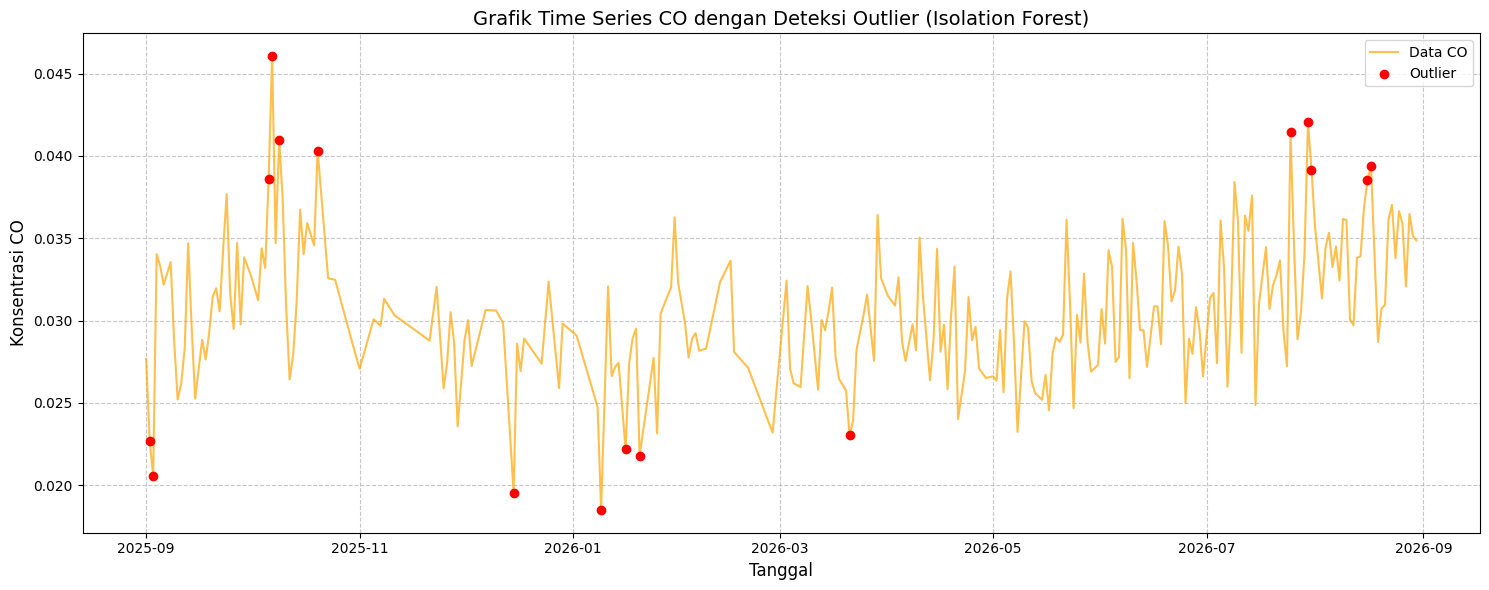

In [13]:
import pandas as pd
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# 1. Load & Clean Data
df = pd.read_csv("../../CO_Timeseries.csv")

df_clean = df.dropna(subset=['CO']).copy()

# 2. Deteksi Outlier
model = IsolationForest(contamination=0.05, random_state=42)
pred = model.fit_predict(df_clean[['CO']])

# Simpan hasil ke dalam dataframe
df_clean['Outlier'] = pred
jumlah_outlier = (df_clean['Outlier'] == -1).sum()
print("Jumlah outlier CO:", jumlah_outlier)

# 3. Visualisasi Grafik Time Series
plt.figure(figsize=(15, 6))

df_clean['date'] = pd.to_datetime(df_clean['date'], dayfirst=True, errors='coerce')

# Ambil titik-titik data yang terdeteksi sebagai outlier
data_outlier = df_clean[df_clean['Outlier'] == -1]

# Plot garis utama untuk data CO
plt.plot(df_clean['date'], df_clean['CO'], color='orange', label='Data CO', alpha=0.7)

# Plot titik merah untuk nilai outlier
plt.scatter(data_outlier['date'], data_outlier['CO'], color='red', label='Outlier', zorder=5)

# Pengaturan visual grafik
plt.title('Grafik Time Series CO dengan Deteksi Outlier (Isolation Forest)', fontsize=14)
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Konsentrasi CO', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Tampilkan grafik
plt.show()

2. SO₂

Jumlah outlier SO2: 16


C:\Users\hp\AppData\Local\Temp\ipykernel_10348\312672529.py:22: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_clean['date'] = pd.to_datetime(df_clean['date'], dayfirst=True, errors='coerce')


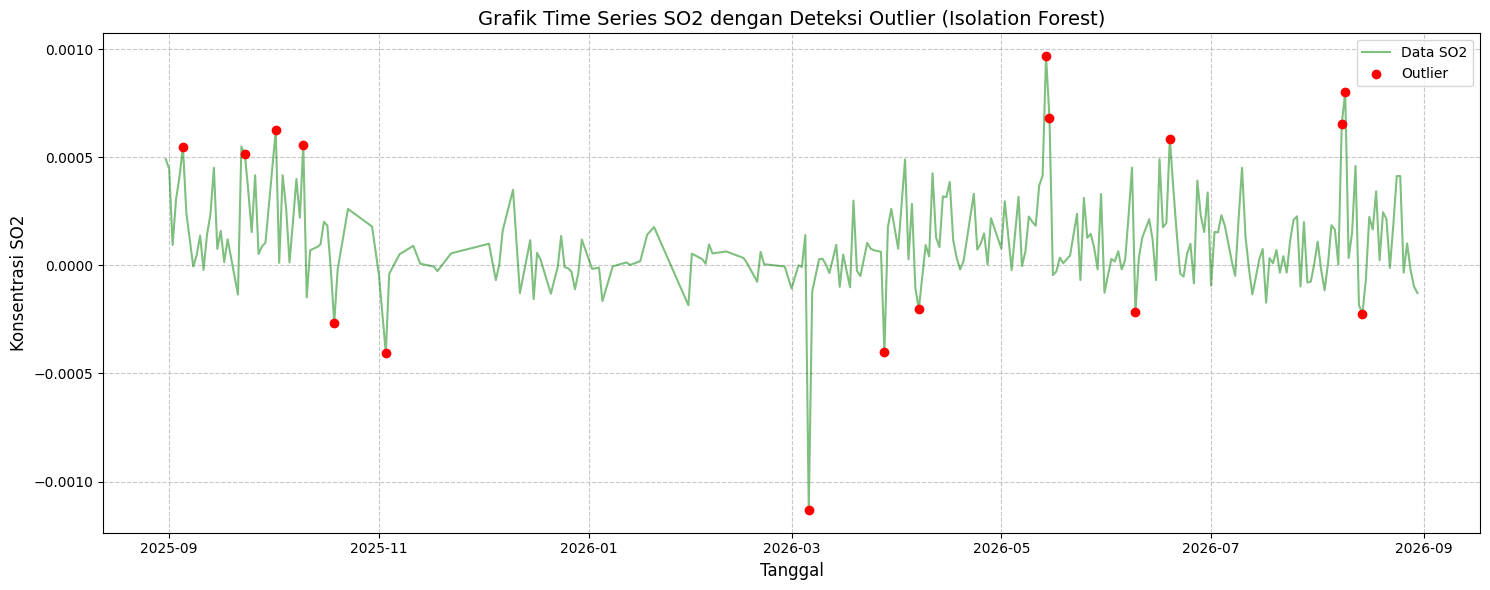

In [14]:
import pandas as pd
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# 1. Load & Clean Data
df = pd.read_csv("../../SO2_Timeseries.csv")

df_clean = df.dropna(subset=['SO2']).copy()

# 2. Deteksi Outlier
model = IsolationForest(contamination=0.05, random_state=42)
pred = model.fit_predict(df_clean[['SO2']])

# Simpan hasil ke dalam dataframe
df_clean['Outlier'] = pred
jumlah_outlier = (df_clean['Outlier'] == -1).sum()
print("Jumlah outlier SO2:", jumlah_outlier)

# 3. Visualisasi Grafik Time Series
plt.figure(figsize=(15, 6))

df_clean['date'] = pd.to_datetime(df_clean['date'], dayfirst=True, errors='coerce')

# Ambil data outlier untuk di-plot secara terpisah
data_outlier = df_clean[df_clean['Outlier'] == -1]

plt.plot(df_clean['date'], df_clean['SO2'], color='green', label='Data SO2', alpha=0.5)

# Plot titik merah untuk nilai outlier
plt.scatter(data_outlier['date'], data_outlier['SO2'], color='red', label='Outlier', zorder=5)

# Pengaturan visual grafik
plt.title('Grafik Time Series SO2 dengan Deteksi Outlier (Isolation Forest)', fontsize=14)
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Konsentrasi SO2', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Tampilkan grafik
plt.show()

3. NO₂

Jumlah outlier: 16


C:\Users\hp\AppData\Local\Temp\ipykernel_10348\1971326150.py:23: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_clean['date'] = pd.to_datetime(df_clean['date'], dayfirst=True, errors='coerce')


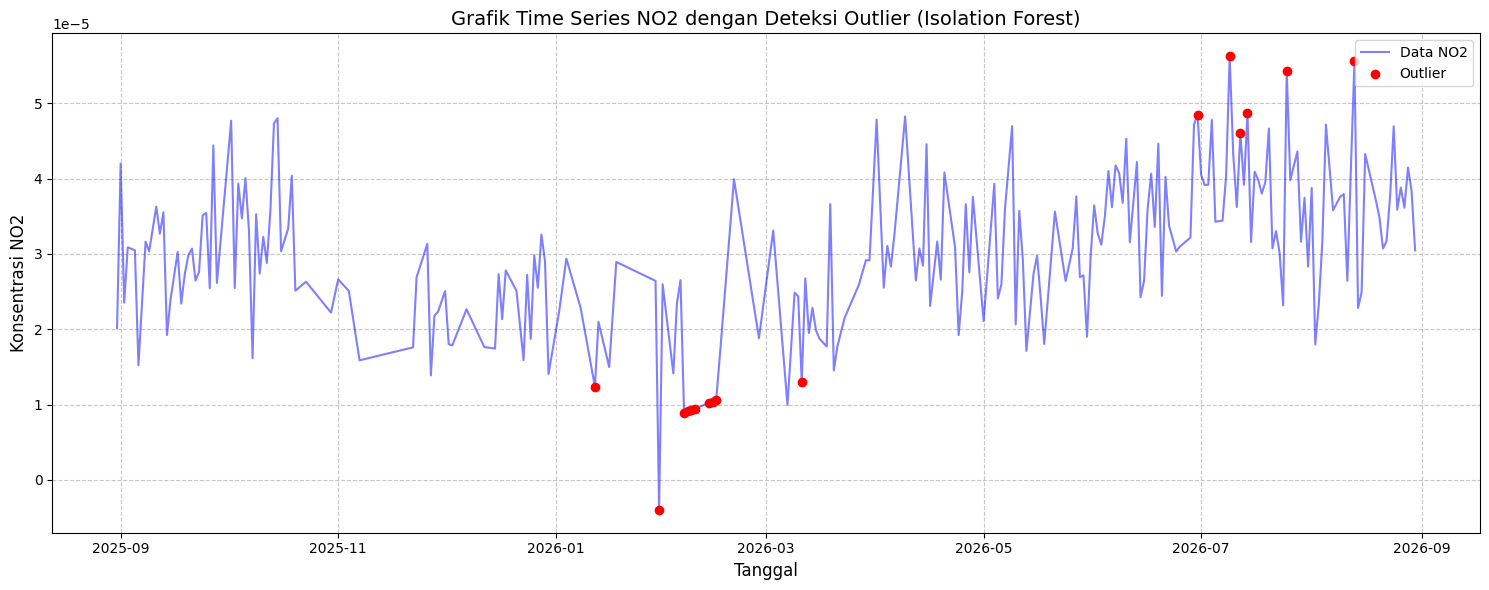

In [15]:
import pandas as pd
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt # Import matplotlib untuk visualisasi

# 1. Load & Clean Data
df = pd.read_csv("../../NO2_Timeseries.csv")
df.columns = ["date", "NO2"]

df_clean = df.dropna(subset=['NO2']).copy()

# 2. Deteksi Outlier
model = IsolationForest(contamination=0.05, random_state=42)
pred = model.fit_predict(df_clean[['NO2']])

# Simpan hasil prediksi ke dalam dataframe untuk mempermudah plotting
df_clean['Outlier'] = pred
jumlah_outlier = (df_clean['Outlier'] == -1).sum()
print("Jumlah outlier:", jumlah_outlier)

# 3. Visualisasi Grafik Time Series
plt.figure(figsize=(15, 6))

df_clean['date'] = pd.to_datetime(df_clean['date'], dayfirst=True, errors='coerce')

# Pisahkan data normal dan outlier
data_normal = df_clean[df_clean['Outlier'] == 1]
data_outlier = df_clean[df_clean['Outlier'] == -1]

# Plot garis utama untuk seluruh data NO2
plt.plot(df_clean['date'], df_clean['NO2'], color='blue', label='Data NO2', alpha=0.5)

# Plot titik merah khusus untuk nilai outlier
plt.scatter(data_outlier['date'], data_outlier['NO2'], color='red', label='Outlier', zorder=5)

# Pengaturan label dan judul
plt.title('Grafik Time Series NO2 dengan Deteksi Outlier (Isolation Forest)', fontsize=14)
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Konsentrasi NO2', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Tampilkan grafik
plt.show()

## Menggabungkan File CSV

Setelah setiap dataset polutan (CO, NO₂, dan SO₂) dianalisis nilai kosong serta pencilan (outlier)-nya, langkah selanjutnya adalah menggunakan dataset gabungan hasil crawling Kecamatan Kertosono. Data tersebut berisi tanggal dan nilai O₃, CO, NO₂, serta SO₂ dalam satu tabel sehingga dapat digunakan untuk analisis multivariat dan pemodelan.

Dataset gabungan dibuat dari tiga file time series yang tersedia. Penggabungan dilakukan berdasarkan kolom tanggal:

File gabungan terbaru berisi kolom `date`, `CO`, `NO2`, dan `SO2`. Nilai kosong sudah dibaca Pandas sebagai `NaN`, sehingga jumlahnya dapat diperiksa langsung dengan `isna().sum()`. Setelah kolom tanggal dikonversi menggunakan `pd.to_datetime`, dataset siap digunakan untuk analisis hubungan antarpolutan, visualisasi, dan pemodelan.

Penggabungan dalam satu file memudahkan pencocokan data berdasarkan tanggal. Namun, sebelum pemodelan, setiap kolom polutan tetap perlu diperiksa tipe datanya, jumlah nilai kosongnya, skala nilainya, dan kemungkinan adanya pencilan. Dengan demikian, dataset gabungan tidak hanya rapi secara struktur, tetapi juga dipahami keterbatasannya.

In [16]:
import pandas as pd

dataframe_polutan = pd.read_csv("../../CO_Timeseries.csv")
dataframe_polutan = dataframe_polutan.merge(
  pd.read_csv("../../SO2_Timeseries.csv"), on="date", how="outer"
)
dataframe_polutan = dataframe_polutan.merge(
  pd.read_csv("../../NO2_Timeseries.csv"), on="date", how="outer"
)
dataframe_polutan["date"] = pd.to_datetime(
  dataframe_polutan["date"], dayfirst=True, errors="coerce"
)
dataframe_polutan.sort_values("date").head()
dataframe_polutan

,date,CO,SO2,NO2
0,2026-01-01,NaN,NaN,NaN
1,2026-02-01,NaN,NaN,NaN
2,2026-03-01,0.027810,NaN,NaN
3,2026-04-01,0.031481,NaN,NaN
4,2026-05-01,0.026613,NaN,NaN
...,...,...,...,...
727,2026-05-31,0.027305,NaN,NaN
728,2026-07-31,0.039170,NaN,NaN
729,2025-08-31,NaN,NaN,NaN
730,2025-10-31,NaN,NaN,NaN


In [17]:
df = dataframe_polutan.sort_values("date").reset_index(drop=True)
df.head(5)

,date,CO,SO2,NO2
0,2025-08-30,NaN,NaN,NaN
1,2025-08-31,NaN,NaN,NaN
2,2025-09-01,0.027680,NaN,NaN
3,2025-09-02,0.022665,NaN,NaN
4,2025-09-03,0.020574,NaN,NaN
